In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

CLEAN_PATH = "D:/New Folder/CLEAN_REFIT_081116/"
OUTPUT_PATH = "D:/New Folder/REFIT_NILM_Results/"

os.makedirs(OUTPUT_PATH, exist_ok=True)

In [2]:
washing_machine_mapping = {
    2: 'Appliance2',
    3: 'Appliance6',
    5: 'Appliance3',
    6: 'Appliance2'
}

household_data = {}

for house, washing_column in washing_machine_mapping.items():

    file_path = os.path.join(
        CLEAN_PATH,
        f"CLEAN_House{house}.csv"
    )

    data = pd.read_csv(
        file_path,
        usecols=[
            'Time',
            'Aggregate',
            washing_column,
            'Issues'
        ]
    )

    data['Time'] = pd.to_datetime(data['Time'])

    data = data.sort_values('Time')

    data = data.rename(
        columns={washing_column: 'Washing_Machine'}
    )

    household_data[house] = data

    print(f"House {house}: {len(data):,} records loaded")

House 2: 5,733,526 records loaded
House 3: 6,994,594 records loaded
House 5: 7,430,755 records loaded
House 6: 6,241,971 records loaded


In [3]:
resampled_data = {}

for house, data in household_data.items():

    valid_data = data[data['Issues'] == 0].copy()

    minute_data = (
        valid_data
        .set_index('Time')[['Aggregate', 'Washing_Machine']]
        .resample('1min')
        .mean()
    )

    resampled_data[house] = minute_data

    print(
        f"House {house}: "
        f"{len(minute_data):,} minutes generated"
    )

House 2: 889,078 minutes generated
House 3: 885,095 minutes generated
House 5: 933,593 minutes generated
House 6: 831,480 minutes generated


In [4]:
for house, data in resampled_data.items():

    print(f"\nHouse {house}")

    print("Total minutes:", len(data))
    print("Missing aggregate:", data['Aggregate'].isna().sum())
    print("Missing washing machine:", data['Washing_Machine'].isna().sum())


House 2
Total minutes: 889078
Missing aggregate: 219633
Missing washing machine: 219633

House 3
Total minutes: 885095
Missing aggregate: 136098
Missing washing machine: 136098

House 5
Total minutes: 933593
Missing aggregate: 123660
Missing washing machine: 123660

House 6
Total minutes: 831480
Missing aggregate: 127626
Missing washing machine: 127626


In [ ]:
model_data = {}

for house, data in resampled_data.items():
    valid = data.dropna(
        subset=['Aggregate', 'Washing_Machine']
    ).copy()
    
    valid = valid[
        (valid['Aggregate'] >= 0) &
        (valid['Washing_Machine'] >= 0)
    ]

    model_data[house] = valid

    print(
        f"House {house}: {len(valid):,} valid modelling records"
    )

House 2: 669,445 valid modelling records
House 3: 748,997 valid modelling records
House 5: 809,933 valid modelling records
House 6: 703,854 valid modelling records


In [6]:
train_houses = [2, 3, 5]
test_house = 6

train_data = pd.concat(
    [model_data[house] for house in train_houses],
    axis=0
)

test_data = model_data[test_house].copy()

X_train = train_data[['Aggregate']]
y_train = train_data['Washing_Machine']

X_test = test_data[['Aggregate']]
y_test = test_data['Washing_Machine']

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2228375
Testing samples: 703854


In [7]:
baseline_model = DummyRegressor(strategy='mean')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_predictions = np.maximum(rf_predictions, 0)

In [10]:
def evaluate_model(y_true, predictions, model_name):

    return {
        'Model': model_name,
        'MAE': mean_absolute_error(y_true, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_true, predictions)),
        'R2_Score': r2_score(y_true, predictions)
    }


results = [
    evaluate_model(
        y_test,
        baseline_predictions,
        'Mean Baseline'
    ),
    evaluate_model(
        y_test,
        rf_predictions,
        'Random Forest'
    )
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,RMSE,R2_Score
0,Mean Baseline,28.0718,102.8463,-0.0218
1,Random Forest,15.0421,93.6514,0.1527


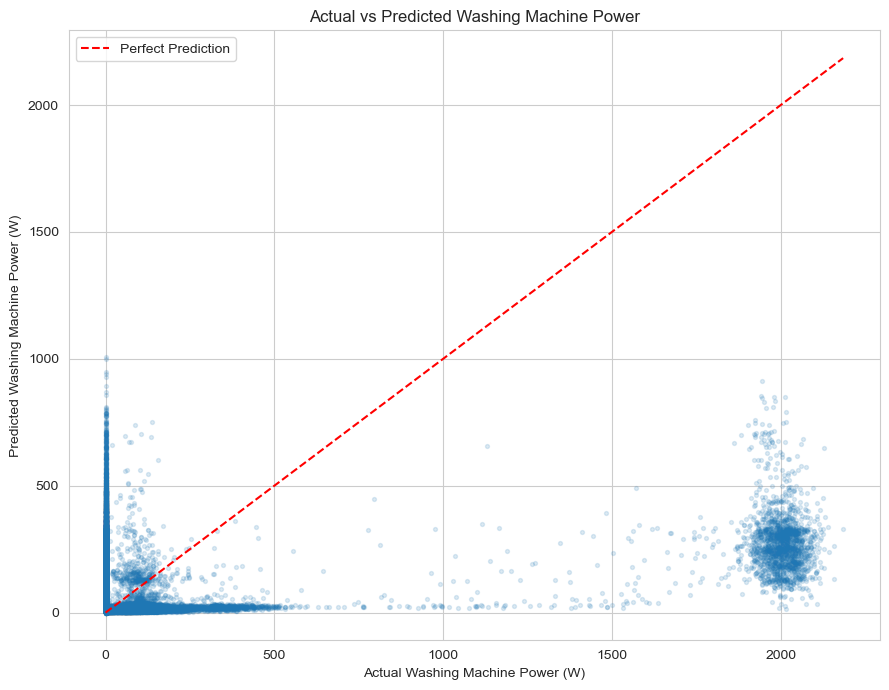

In [11]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.15,
    s=8
)

max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Washing Machine Power (W)')
plt.ylabel('Predicted Washing Machine Power (W)')
plt.title('Actual vs Predicted Washing Machine Power')
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, 'actual_vs_predicted.png'),
    dpi=300
)

plt.show()

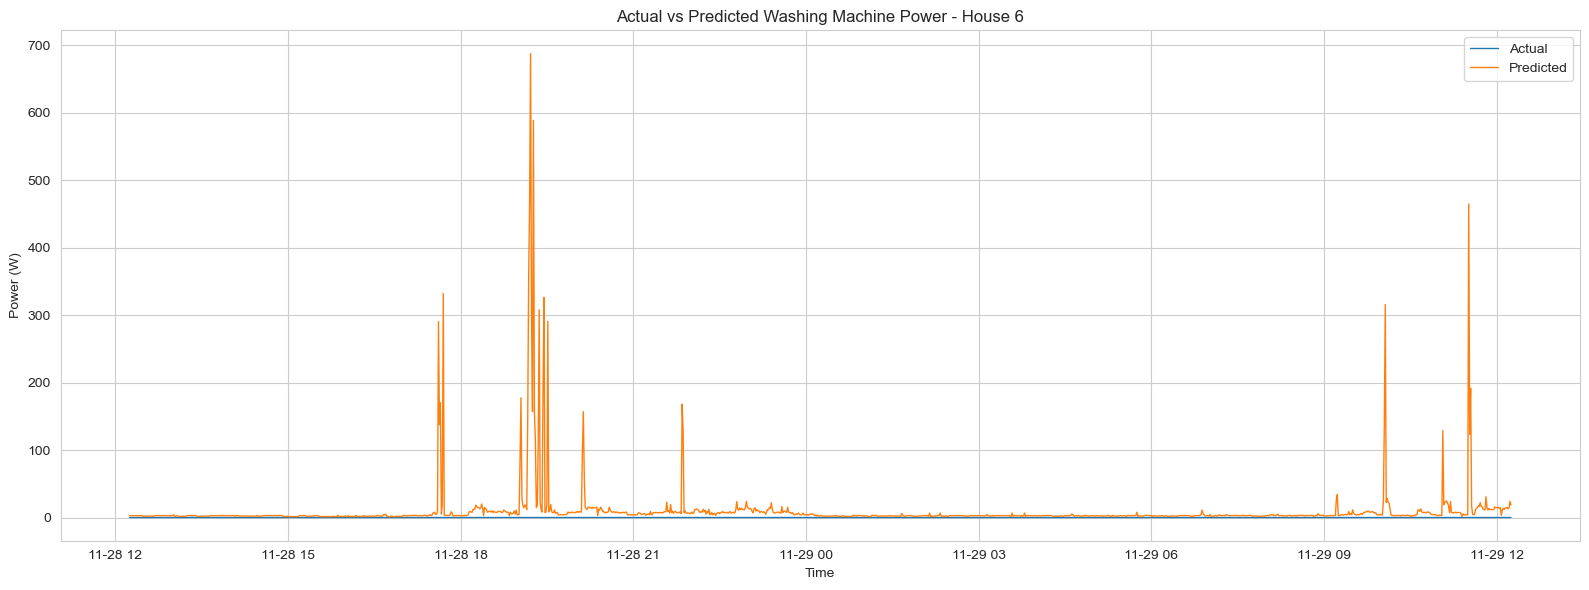

In [ ]:
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': rf_predictions
}, index=y_test.index)

sample_start = comparison_df.index.min()
sample_end = sample_start + pd.Timedelta(days=1)

sample = comparison_df.loc[sample_start:sample_end]

plt.figure(figsize=(16, 6))

plt.plot(
    sample.index,
    sample['Actual'],
    label='Actual',
    linewidth=1
)

plt.plot(
    sample.index,
    sample['Predicted'],
    label='Predicted',
    linewidth=1
)

plt.xlabel('Time')
plt.ylabel('Power (W)')
plt.title('Actual vs Predicted Washing Machine Power - House 6')
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, 'prediction_time_series.png'),
    dpi=300
)

plt.show()

In [13]:
active_mask = y_test > 200

active_metrics = {
    'Active_Test_Minutes': active_mask.sum(),
    'Active_MAE': mean_absolute_error(
        y_test[active_mask],
        rf_predictions[active_mask]
    ),
    'Active_RMSE': np.sqrt(
        mean_squared_error(
            y_test[active_mask],
            rf_predictions[active_mask]
        )
    )
}

display(pd.DataFrame([active_metrics]).round(3))

,Active_Test_Minutes,Active_MAE,Active_RMSE
0,2835,1198.581,1381.617


In [ ]:
feature_data = {}

for house, data in resampled_data.items():

    df = data.copy()

    df['Aggregate_Current'] = df['Aggregate']

    df['Aggregate_Lag_1'] = df['Aggregate'].shift(1)
    df['Aggregate_Lag_5'] = df['Aggregate'].shift(5)
    df['Aggregate_Lag_10'] = df['Aggregate'].shift(10)

    df['Aggregate_Rolling_5'] = (
        df['Aggregate'].rolling(5).mean()
    )

    df['Aggregate_Rolling_10'] = (
        df['Aggregate'].rolling(10).mean()
    )

    df['Aggregate_Change'] = df['Aggregate'].diff()

    df = df.dropna()

    feature_data[house] = df

    print(f"House {house}: {len(df):,} feature records")

House 2: 662,994 feature records
House 3: 721,597 feature records
House 5: 765,444 feature records
House 6: 690,194 feature records


In [15]:
feature_columns = [
    'Aggregate_Current',
    'Aggregate_Lag_1',
    'Aggregate_Lag_5',
    'Aggregate_Lag_10',
    'Aggregate_Rolling_5',
    'Aggregate_Rolling_10',
    'Aggregate_Change'
]

train_data_v2 = pd.concat([
    feature_data[2],
    feature_data[3],
    feature_data[5]
])

test_data_v2 = feature_data[6].copy()

X_train_v2 = train_data_v2[feature_columns]
y_train_v2 = train_data_v2['Washing_Machine']

X_test_v2 = test_data_v2[feature_columns]
y_test_v2 = test_data_v2['Washing_Machine']

print("Training samples:", len(X_train_v2))
print("Testing samples:", len(X_test_v2))

Training samples: 2150035
Testing samples: 690194


In [16]:
rf_model_v2 = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

rf_predictions_v2 = rf_model_v2.predict(X_test_v2)

rf_predictions_v2 = np.maximum(rf_predictions_v2, 0)

In [17]:
improved_results = [
    evaluate_model(
        y_test_v2,
        baseline_model.predict(X_test_v2[['Aggregate_Current']]),
        'Mean Baseline'
    ),
    evaluate_model(
        y_test_v2,
        rf_predictions_v2,
        'Random Forest - Temporal Features'
    )
]

improved_results_df = pd.DataFrame(improved_results)

display(improved_results_df.round(4))

,Model,MAE,RMSE,R2_Score
0,Mean Baseline,28.1082,103.2316,-0.0215
1,Random Forest - Temporal Features,13.9797,83.6482,0.3293


In [18]:
active_mask_v2 = y_test_v2 > 200

active_results_v2 = {
    'Active_Test_Minutes': active_mask_v2.sum(),
    'Active_MAE': mean_absolute_error(
        y_test_v2[active_mask_v2],
        rf_predictions_v2[active_mask_v2]
    ),
    'Active_RMSE': np.sqrt(
        mean_squared_error(
            y_test_v2[active_mask_v2],
            rf_predictions_v2[active_mask_v2]
        )
    )
}

display(pd.DataFrame([active_results_v2]).round(3))

,Active_Test_Minutes,Active_MAE,Active_RMSE
0,2794,1036.633,1209.405


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [21]:
ON_THRESHOLD = 200

y_train_binary = (
    y_train_v2 > ON_THRESHOLD
).astype(int)

y_test_binary = (
    y_test_v2 > ON_THRESHOLD
).astype(int)

print("Training ON minutes:", y_train_binary.sum())
print("Training OFF minutes:", (y_train_binary == 0).sum())

print("Testing ON minutes:", y_test_binary.sum())
print("Testing OFF minutes:", (y_test_binary == 0).sum())

Training ON minutes: 31284
Training OFF minutes: 2118751
Testing ON minutes: 2794
Testing OFF minutes: 687400


In [ ]:
from sklearn.ensemble import RandomForestClassifier

classifier_train = training_sample.sample(
    n=min(400000, len(training_sample)),
    random_state=42
)

X_classifier_train = classifier_train.drop(
    columns=['Target']
).astype(np.float32)

y_classifier_train = classifier_train['Target']

print("Training records:", len(X_classifier_train))
print("OFF percentage:", (y_classifier_train == 0).mean() * 100)
print("ON percentage:", (y_classifier_train == 1).mean() * 100)

classifier = RandomForestClassifier(
    n_estimators=80,
    max_depth=12,
    min_samples_leaf=10,
    class_weight=None,
    random_state=42,
    n_jobs=1
)

classifier.fit(
    X_classifier_train,
    y_classifier_train
)

state_predictions = classifier.predict(X_test_memory)

Training records: 400000
OFF percentage: 98.54125
ON percentage: 1.45875


In [30]:
classification_results = {
    'Accuracy': accuracy_score(
        y_test_binary,
        state_predictions
    ),
    'Precision': precision_score(
        y_test_binary,
        state_predictions,
        zero_division=0
    ),
    'Recall': recall_score(
        y_test_binary,
        state_predictions,
        zero_division=0
    ),
    'F1_Score': f1_score(
        y_test_binary,
        state_predictions,
        zero_division=0
    )
}

display(
    pd.DataFrame([classification_results]).round(4)
)

print(
    classification_report(
        y_test_binary,
        state_predictions,
        target_names=['OFF', 'ON'],
        zero_division=0
    )
)

,Accuracy,Precision,Recall,F1_Score
0,0.996,0.8667,0.0047,0.0093


              precision    recall  f1-score   support

         OFF       1.00      1.00      1.00    687400
          ON       0.87      0.00      0.01      2794

    accuracy                           1.00    690194
   macro avg       0.93      0.50      0.50    690194
weighted avg       1.00      1.00      0.99    690194



In [31]:
active_train_mask = y_train_v2 > ON_THRESHOLD

power_regressor = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

power_regressor.fit(
    X_train_v2.loc[active_train_mask],
    y_train_v2.loc[active_train_mask]
)

RandomForestRegressor(max_depth=20, min_samples_leaf=3, n_estimators=150,
                      n_jobs=-1, random_state=42)

In [32]:
final_predictions = np.zeros(len(X_test_memory))

predicted_on_mask = state_predictions == 1

final_predictions[predicted_on_mask] = (
    power_regressor.predict(
        X_test_v2.loc[predicted_on_mask]
    )
)

final_predictions = np.maximum(final_predictions, 0)

In [37]:
two_stage_results = {
    'MAE': mean_absolute_error(
        y_test_v2,
        final_predictions
    ),
    'RMSE': np.sqrt(
        mean_squared_error(
            y_test_v2,
            final_predictions
        )
    ),
    'R2_Score': r2_score(
        y_test_v2,
        final_predictions
    ),
    'Active_MAE': mean_absolute_error(
        y_test_v2[y_test_v2 > ON_THRESHOLD],
        final_predictions[y_test_v2 > ON_THRESHOLD]
    ),
    'Active_RMSE': np.sqrt(
        mean_squared_error(
            y_test_v2[y_test_v2 > ON_THRESHOLD],
            final_predictions[y_test_v2 > ON_THRESHOLD]
        )
    )
}

display(
    pd.DataFrame([two_stage_results]).round(4)
)

,MAE,RMSE,R2_Score,Active_MAE,Active_RMSE
0,6.9495,102.0771,0.0012,1376.5795,1592.3337


In [36]:
from sklearn.metrics import confusion_matrix, classification_report

print("Actual ON percentage:",
      (y_test_binary == 1).mean() * 100)

print("Predicted ON percentage:",
      (state_predictions == 1).mean() * 100)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test_binary,
        state_predictions
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test_binary,
        state_predictions,
        target_names=['OFF', 'ON'],
        zero_division=0
    )
)

print("\nPrediction Statistics:")

print(pd.Series(final_predictions).describe())

Actual ON percentage: 0.404813719041313
Predicted ON percentage: 0.0021733019991480654

Confusion Matrix:
[[687398      2]
 [  2781     13]]

Classification Report:
              precision    recall  f1-score   support

         OFF       1.00      1.00      1.00    687400
          ON       0.87      0.00      0.01      2794

    accuracy                           1.00    690194
   macro avg       0.93      0.50      0.50    690194
weighted avg       1.00      1.00      0.99    690194


Prediction Statistics:
count    690194.000000
mean          0.040345
std           8.657287
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        1950.168908
dtype: float64


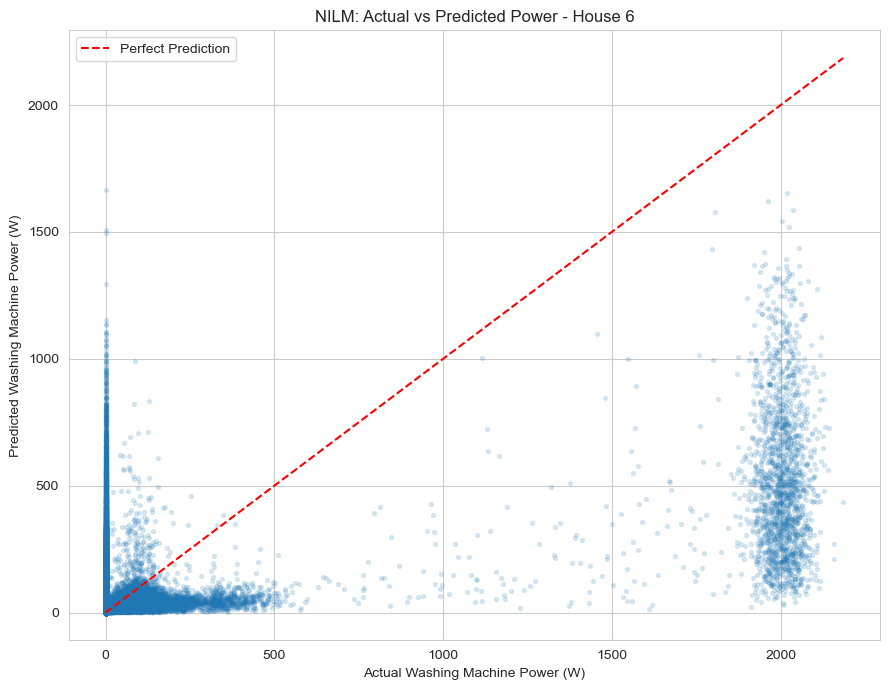

In [38]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test_v2,
    rf_predictions_v2,
    alpha=0.15,
    s=8
)

max_value = max(
    y_test_v2.max(),
    rf_predictions_v2.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Washing Machine Power (W)')
plt.ylabel('Predicted Washing Machine Power (W)')
plt.title('NILM: Actual vs Predicted Power - House 6')
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, 'final_actual_vs_predicted.png'),
    dpi=300
)

plt.show()

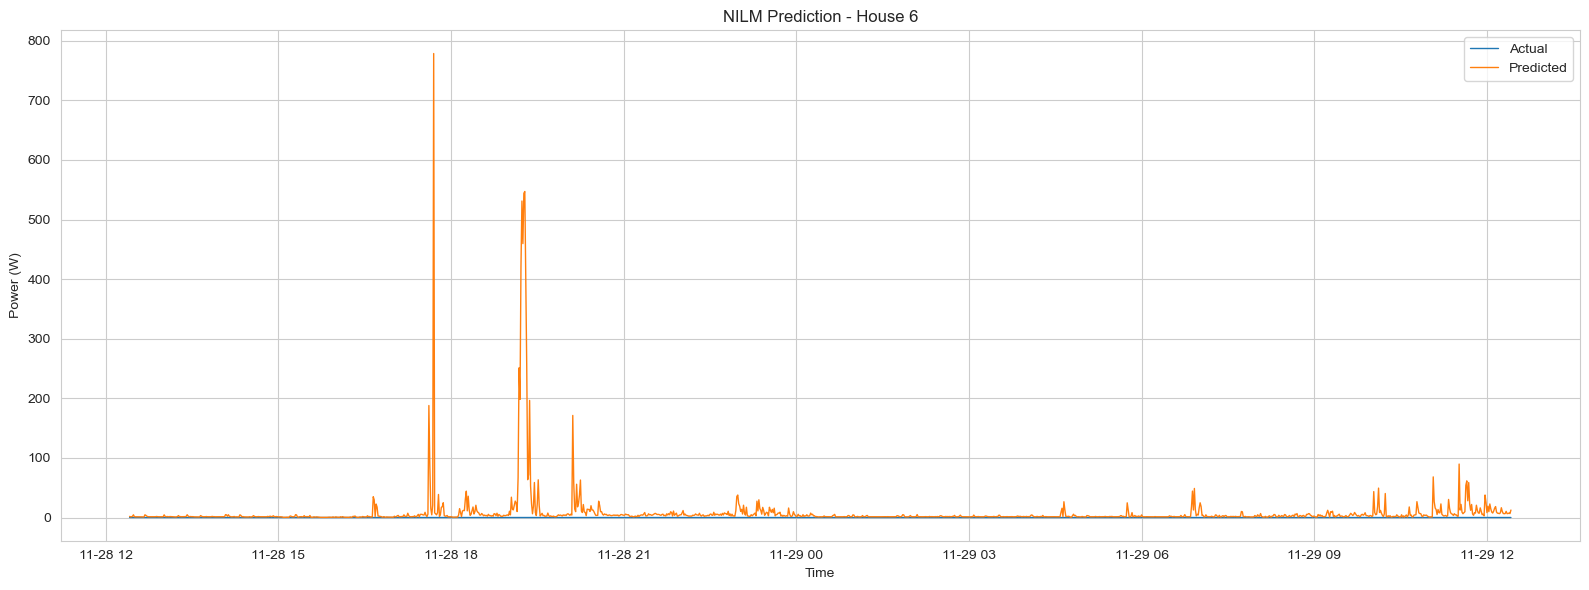

In [39]:
comparison_df = pd.DataFrame({
    'Actual': y_test_v2,
    'Predicted': rf_predictions_v2
}, index=y_test_v2.index)

sample_start = comparison_df.index.min()
sample_end = sample_start + pd.Timedelta(days=1)

sample = comparison_df.loc[sample_start:sample_end]

plt.figure(figsize=(16, 6))

plt.plot(
    sample.index,
    sample['Actual'],
    label='Actual',
    linewidth=1
)

plt.plot(
    sample.index,
    sample['Predicted'],
    label='Predicted',
    linewidth=1
)

plt.xlabel('Time')
plt.ylabel('Power (W)')
plt.title('NILM Prediction - House 6')
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, 'final_prediction_timeseries.png'),
    dpi=300
)

plt.show()

In [40]:
final_metrics = evaluate_model(
    y_test_v2,
    rf_predictions_v2,
    'Random Forest - Temporal Features'
)

active_mask = y_test_v2 > 200

final_metrics.update({
    'Active_MAE': mean_absolute_error(
        y_test_v2[active_mask],
        rf_predictions_v2[active_mask]
    ),
    'Active_RMSE': np.sqrt(
        mean_squared_error(
            y_test_v2[active_mask],
            rf_predictions_v2[active_mask]
        )
    )
})

final_results_df = pd.DataFrame([final_metrics])

display(final_results_df.round(4))

final_results_df.to_csv(
    os.path.join(OUTPUT_PATH, 'final_nilm_results.csv'),
    index=False
)

,Model,MAE,RMSE,R2_Score,Active_MAE,Active_RMSE
0,Random Forest - Temporal Features,13.9797,83.6482,0.3293,1036.6328,1209.4052
